In [7]:
import pandas as pnd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
import keras

In [8]:
tf.config.set_visible_devices([], 'GPU')

LONGUEUR_IMAGE = 28
LARGEUR_IMAGE = 28

observation_entrainement = pnd.read_csv('data/fashion-mnist_test.csv')

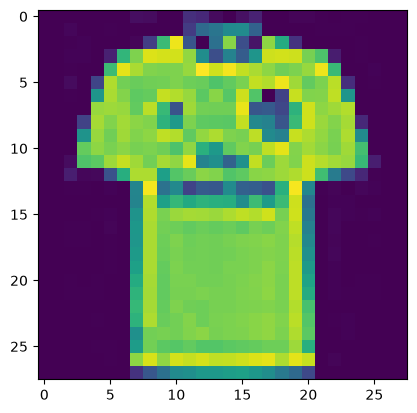

In [9]:
X = np.array(observation_entrainement.iloc[:, 1:])

premiereImage = X[0]
premiereImage = premiereImage.reshape([LONGUEUR_IMAGE, LARGEUR_IMAGE])
plt.imshow(premiereImage)
plt.show()

In [10]:
Y = keras.utils.to_categorical(np.array(observation_entrainement.iloc[:, 0]))

X_apprentissage, X_validation, Y_apprentissage, Y_validation = train_test_split(X, Y, test_size = 0.2, random_state = 13)

In [11]:
X_apprentissage = X_apprentissage.reshape(X_apprentissage.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_apprentissage = X_apprentissage.astype('float32')
X_apprentissage /= 255

X_validation = X_validation.reshape(X_validation.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

X_validation = X_validation.astype('float32')
X_validation /= 255

In [12]:
observation_test = pnd.read_csv('data/fashion-mnist_test.csv')
X_test = np.array(observation_test.iloc[:, 1:])
Y_test = tf.keras.utils.to_categorical(np.array(observation_test.iloc[:, 0]))
X_test = X_test.reshape(X_test.shape[0], LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)
X_test = X_test.astype('float32')
X_test /= 255

In [13]:
from keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Input
from keras.layers import Conv2D, MaxPooling2D

In [14]:
dimentionImage = (LARGEUR_IMAGE, LONGUEUR_IMAGE, 1)

reseauNeurone1Convolution = Sequential()

reseauNeurone1Convolution.add(Input(shape = dimentionImage))
reseauNeurone1Convolution.add(Conv2D(32, kernel_size = (3, 3), activation = 'relu'))
reseauNeurone1Convolution.add(MaxPooling2D(pool_size = (2, 2)))
reseauNeurone1Convolution.add(Dropout(0.2))
reseauNeurone1Convolution.add(Flatten())
reseauNeurone1Convolution.add(Dense(128, activation = 'relu'))
reseauNeurone1Convolution.add(Dense(10, activation = 'softmax'))

In [15]:
reseauNeurone1Convolution.compile(loss = keras.losses.categorical_crossentropy, optimizer = tf.keras.optimizers.Adam(), metrics = ['accuracy'])

In [16]:
historique_apprentissage = reseauNeurone1Convolution.fit(X_apprentissage, Y_apprentissage, batch_size = 256, epochs = 10, verbose = 1, validation_data = (X_validation, Y_validation))

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.6743 - loss: 0.9953 - val_accuracy: 0.8045 - val_loss: 0.5619
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.8075 - loss: 0.5451 - val_accuracy: 0.8195 - val_loss: 0.5063
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8374 - loss: 0.4644 - val_accuracy: 0.8420 - val_loss: 0.4541
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8564 - loss: 0.4111 - val_accuracy: 0.8545 - val_loss: 0.4129
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8677 - loss: 0.3772 - val_accuracy: 0.8670 - val_loss: 0.3903
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.8701 - loss: 0.3630 - val_accuracy: 0.8695 - val_loss: 0.3757
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.8800 - loss: 0.3377 - val_accuracy: 0.8715 - val_loss: 0.3681
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.8917 - loss: 0.3127 - val_accuracy: 0.8740 - v

In [17]:
evaluation = reseauNeurone1Convolution.evaluate(X_test, Y_test, verbose = 0)
print('Erreur : ', evaluation[0])
print('Precision : ', evaluation[1])

Erreur :  0.27229082584381104
Precision :  0.9072999954223633


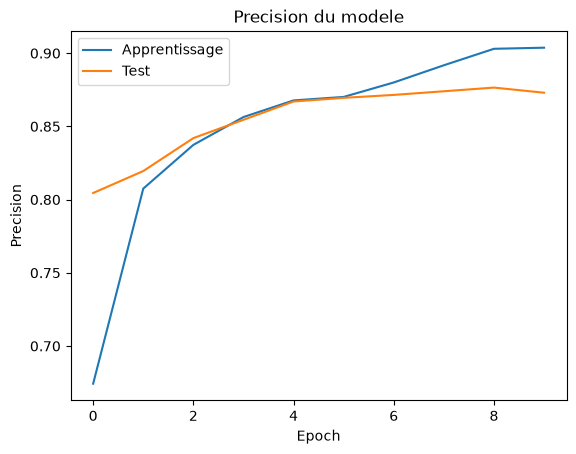

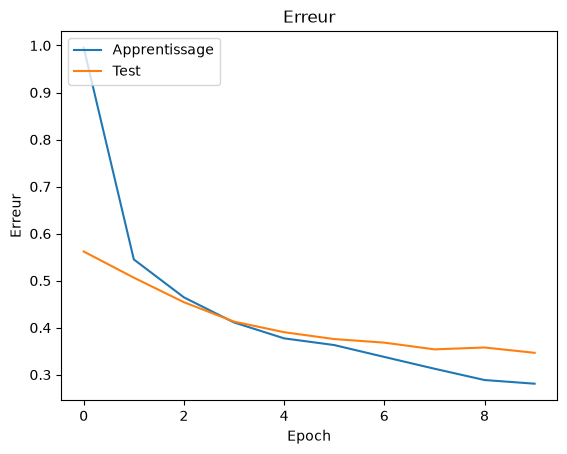

In [18]:
plt.plot(historique_apprentissage.history['accuracy'])
plt.plot(historique_apprentissage.history['val_accuracy'])
plt.title('Precision du modele')
plt.ylabel('Precision')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc = 'upper left')
plt.show()

plt.plot(historique_apprentissage.history['loss'])
plt.plot(historique_apprentissage.history['val_loss'])
plt.title('Erreur')
plt.ylabel('Erreur')
plt.xlabel('Epoch')
plt.legend(['Apprentissage', 'Test'], loc = 'upper left')
plt.show()

In [19]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [20]:
generateur_images = ImageDataGenerator(rotation_range = 8, width_shift_range = 0.08, shear_range = 0.3, height_shift_range = 0.08, zoom_range = 0.08)

In [22]:
nouvelles_images_apprentissage = generateur_images.flow(X_apprentissage, Y_apprentissage, batch_size = 256)

nouvelles_images_validation = generateur_images.flow(X_validation, Y_validation, batch_size = 256)

historique_apprentissage = reseauNeurone1Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch = 48000//256, epochs = 50, validation_data = nouvelles_images_validation, validation_steps = 12000//256, verbose = 1)

evaluation = reseauNeurone1Convolution.evaluate(X_test, Y_test, verbose = 0)

print('Erreur : ', evaluation)
print('Precision : ', evaluation)

Epoch 1/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8779 - loss: 0.3218 - val_accuracy: 0.8595 - val_loss: 0.3624
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8726 - loss: 0.3240 - val_accuracy: 0.8655 - val_loss: 0.3726
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8789 - loss: 0.3197 - val_accuracy: 0.8680 - val_loss: 0.3545
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8795 - loss: 0.3088 - val_accuracy: 0.8655 - val_loss: 0.3662
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8816 - loss: 0.3089 - val_accuracy: 0.8605 - val_loss: 0.3860
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8744 - loss: 0.3234 - val_accuracy: 0.8750 - val_loss: 0.3563
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.8832 - loss: 0.3074 - val_accuracy: 0.8680 - val_loss: 0.3474
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.8840 - loss: 0.3093 - val_accu

In [24]:
model_json = reseauNeurone1Convolution.to_json()

with open("modele/modele.json", "w") as json_file:
    json_file.write(model_json)
    
reseauNeurone1Convolution.save_weights("modele/modele.weights.h5")
print("Modele sauvegarde!")

Modele sauvegarde!


In [25]:
from keras.layers import BatchNormalization

In [26]:
reseauNeurones4Convolution = Sequential()

reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=dimentionImage))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Conv2D(32, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(64, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Conv2D(128, kernel_size=(3, 3), activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(MaxPooling2D(pool_size=(2, 2)))
reseauNeurones4Convolution.add(Dropout(0.25))

reseauNeurones4Convolution.add(Flatten())
reseauNeurones4Convolution.add(Dense(512, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(128, activation='relu'))
reseauNeurones4Convolution.add(BatchNormalization())
reseauNeurones4Convolution.add(Dropout(0.5))

reseauNeurones4Convolution.add(Dense(10, activation='softmax'))

c:\VS Code\Techno_session_8\Atelier_1\420-5G4-ML-Groupe-3\apprentissage\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
reseauNeurones4Convolution.compile(loss = keras.losses.categorical_crossentropy, optimizer = tf.keras.optimizers.Adam(), metrics = ['accuracy'])

historique_apprentissage = reseauNeurones4Convolution.fit(X_apprentissage, Y_apprentissage, batch_size = 256, epochs = 10, verbose = 1, validation_data = (X_validation, Y_validation))

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 327ms/step - accuracy: 0.5713 - loss: 1.3775 - val_accuracy: 0.0950 - val_loss: 2.5487
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 307ms/step - accuracy: 0.7222 - loss: 0.7748 - val_accuracy: 0.0950 - val_loss: 2.8009
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 307ms/step - accuracy: 0.7573 - loss: 0.6564 - val_accuracy: 0.0950 - val_loss: 2.9576
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 308ms/step - accuracy: 0.7820 - loss: 0.5900 - val_accuracy: 0.1795 - val_loss: 3.0689
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 307ms/step - accuracy: 0.8075 - loss: 0.5221 - val_accuracy: 0.1875 - val_loss: 3.2044
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 309ms/step - accuracy: 0.8179 - loss: 0.5007 - val_accuracy: 0.2740 - val_loss: 2.7068
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 309ms/step - accuracy: 0.8328 - loss: 0.4587 - val_accuracy: 0.2455 - val_loss: 2.4686
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 306ms/step - accuracy: 0.8436 - loss: 0.4280 - val_accu

In [28]:
evaluation = reseauNeurones4Convolution.evaluate(X_test, Y_test, verbose = 0)

print('Erreur :', evaluation[0])
print('Précision :', evaluation[1])

Erreur : 2.1173934936523438
Précision : 0.46399998664855957


In [29]:
historique_apprentissage = reseauNeurones4Convolution.fit(nouvelles_images_apprentissage, steps_per_epoch = 48000//256, epochs = 50, validation_data = nouvelles_images_validation, validation_steps = 12000//256, verbose = 1)

evaluation = reseauNeurones4Convolution.evaluate(X_test, Y_test, verbose = 0)

print('Erreur : ', evaluation[0])
print('Précision : ', evaluation[1])

Epoch 1/50
 32/187 ━━━━━━━━━━━━━━━━━━━━ 48s 315ms/step - accuracy: 0.7705 - loss: 0.6300

c:\VS Code\Techno_session_8\Atelier_1\420-5G4-ML-Groupe-3\apprentissage\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


187/187 ━━━━━━━━━━━━━━━━━━━━ 14s 59ms/step - accuracy: 0.7705 - loss: 0.6300 - val_accuracy: 0.4875 - val_loss: 2.0658
Epoch 2/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.7931 - loss: 0.5519 - val_accuracy: 0.4625 - val_loss: 2.0891
Epoch 3/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8073 - loss: 0.5158 - val_accuracy: 0.5015 - val_loss: 1.8223
Epoch 4/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8059 - loss: 0.5105 - val_accuracy: 0.5940 - val_loss: 1.2510
Epoch 5/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 12s 60ms/step - accuracy: 0.8204 - loss: 0.4924 - val_accuracy: 0.6305 - val_loss: 1.1999
Epoch 6/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8310 - loss: 0.4640 - val_accuracy: 0.6830 - val_loss: 0.9071
Epoch 7/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.8207 - loss: 0.4647 - val_accuracy: 0.7390 - val_loss: 0.7429
Epoch 8/50
187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 57ms/step - accuracy: 0.8355 - loss: 0.4477 - val_accurac